# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [10]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.11.9 | packaged by Anaconda, Inc. | (main, Apr 19 2024, 16:40:41) [MSC v.1916 64 bit (AMD64)]
System  : Windows 10


In [11]:
!pip --version

pip 23.3.1 from C:\Users\Dell\.conda\envs\DATA\Lib\site-packages\pip (python 3.11)



### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [12]:
!ollama --version

ollama version is 0.40.3


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [13]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [15]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3:4b"       # Model 1
MODEL2 = "llama3.2:3b"     # Model 2 (used in the comparison parts)

In [14]:
!ollama list

NAME           ID              SIZE      MODIFIED    
llava:7b       8dd30f6b0cb1    4.7 GB    9 days ago     
llama3.2:3b    a80c4f17acd5    2.0 GB    11 days ago    
qwen3:4b       359d7dd4bcda    2.5 GB    11 days ago    


### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [17]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [18]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[62.1s]
Artificial intelligence (AI) refers to computer systems designed to perform tasks that typically require human intelligence. These systems simulate cognitive functions like learning, problem-solving, perception, and decision-making through complex algorithms and data processing. AI models improve their performance by analyzing vast amounts of data, identifying patterns, and adapting to new information over time. Real-world applications range from natural language processing and robotics to medical diagnosis and personalized recommendations. Crucially, AI does not possess human consciousness or understanding—it operates as a tool that mimics intelligent behavior within defined parameters.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[175.1s]
Hey there! 🌟 Imagine your phone is like a **super-smart friend** that *learns* things just by watching you play games, listen to music, or eat pizza 🍕.

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

### Answer/Exercise 4

1.  Yes, I noticed that the model generated different answers depending on the prompt. For the first prompt it gave a general definition of artificial intelligence. For the second prompt, it used simple words and examples to explain AI to a child. For the third prompt, it provided a more technical and detailed explanation suitable for a computer science professor.
2.  No I used Ollama to run the Qwen3 4B model locally on my computer. The requests were sent to the local Ollama API, so I did not need to use an external cloud AI service to generate the responses.
3.  Inference is performed locally on my computer using its hardware resources, such as the CPU and/or GPU. The model processes the prompts and generates the answers directly on my machine.
4.  I disabled my Wi-Fi connection and ran the model again using Ollama. The model continued to work normally and generated responses without any Internet connection.


## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [19]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[413.1s]
### Professor's Explanation: Directed Acyclic Graph (D. A. G.)

**1. Definition**  
A *Directed Acyclic Graph (DAG)* is a directed graph (where edges have a direction) that contains **no cycles**—meaning there is no sequence of edges that starts and ends at the same vertex without repeating vertices. Formally, a DAG is a graph $G = (V, E)$ where:  
- $V$ is a finite set of vertices,  
- $E \subseteq V \times V$ is a set of directed edges (arcs),  
- **No cycles exist**: For any vertex $v \in V$, there is no path $v \to v$ (i.e., traversing edges without revisiting vertices).  

This contrasts with cyclic graphs (e.g., cycles in social networks) where cycles would violate the *acyclic* property. DAGs are crucial for modeling **partial orders** (e.g., task dependencies) because cycles would imply impossible constraints (e.g., "Task A must happen before Task A").

---

**2. Example**  
Consider a project management scenario where tasks must be completed in specific orders:  
- **

In [20]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[322.6s]
### Explaining DAGs to a First-Year CS Student (Simple & Concrete)

**Hi there!** 👋 As your professor, I’ll explain **DAGs** (Directed Acyclic Graphs) using **pizza-making**—a topic *every* first-year CS student can relate to. No jargon, no math, just plain English and one clear example. Let’s go!

---

### 🔍 What is a DAG? (In 10 Seconds)
A **DAG** is like a **"step-by-step instruction list"** where:
1. **You can’t go back** (no cycles).  
2. **Some steps depend on others** (like "you need to make sauce *before* adding cheese").  
3. **It’s not a cycle** (e.g., you *can’t* do "sauce" after "sauce" again).

> 💡 **Key phrase for you**: *"DAG = Step-by-step instructions with no loops."*

---

### 🍕 One Concrete Example: Making Pizza (The BEST Example for Beginners)
Imagine you’re making pizza. Here’s what you **must do** in order (with dependencies):

| Step | What to Do              | **Depends On** (Why it must happen first) |
|------|-------------------------|----------------

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

### Answer

Prompt A produced a technical and detailed explanation, including mathematical definitions, an adjacency matrix, real-world applications, and Python code.

Prompt B generated a simpler explanation using a pizza-making example, making the concept easier for a first-year computer science student to understand.

- Role: The role defines how the model should behave. In both prompts, the model adopted a teaching role, but the explanations were adapted to different audiences.

- Context: The context provides information about the situation and the target audience. Prompt A was oriented toward an advanced academic explanation, while Prompt B focused on teaching a beginner.

- Constraints: Constraints define the limits and requirements of the response. Prompt A included technical elements such as mathematical definitions and Python code, while Prompt B avoided complex terminology and mathematics.

- Output format: The output format determines how the information is presented. Prompt A generated a structured technical explanation with sections, a table, and code. Prompt B used a simpler structure with short explanations, examples, and a visual representation.

- Specificity: Specific instructions help the model understand what is expected. Both prompts were specific about the audience and explanation style, which helped produce responses adapted to their objectives.

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [21]:
!ollama list

NAME              ID              SIZE      MODIFIED       
qwen3.5:latest    56671c2ab938    6.6 GB    42 minutes ago    
qwen3:4b          359d7dd4bcda    2.5 GB    44 minutes ago    
llava:7b          8dd30f6b0cb1    4.7 GB    9 days ago        
llama3.2:3b       a80c4f17acd5    2.0 GB    11 days ago       


In [22]:
!ollama show {MODEL}

  Model
    architecture        qwen3     
    parameters          4.0B      
    context length      262144    
    embedding length    2560      
    quantization        Q4_K_M    

  Capabilities
    completion     
    tools          
    thinking       
        levels     true    
        default    true    

  Parameters
    repeat_penalty    1                 
    stop              "<|im_start|>"    
    stop              "<|im_end|>"      
    temperature       0.6               
    top_k             20                
    top_p             0.95              

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [23]:
!ollama ps

NAME    ID    SIZE    PROCESSOR    CONTEXT    RUNNER    UNTIL 


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [28]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:latest,6.55,qwen35,9.0B,Q4_K_M
1,qwen3:4b,2.50,qwen3,4.0B,Q4_K_M
2,llava:7b,4.73,llama,7B,Q4_0
3,llama3.2:3b,2.02,llama,3.2B,Q4_K_M


Currently loaded in memory:


""


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

### Answer

1. ollama list displays models downloaded to local storage. ollama ps displays models currently loaded for inference.

2. A downloaded model has its files saved on disk and is available to run. A loaded model has been brought into RAM and/or VRAM for inference. A model can be downloaded without currently being loaded.

## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [29]:
!ollama pull {MODEL2}
!ollama list

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest 
pulling dde5aa3fc5ff: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 2.0 GB                         
pulling 966de95ca8a6: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 1.4 KB                         
pulling fcc5a6bec9da: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 7.7 KB                         
pulling a70ff7e570d9: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 6.0 KB                         
pulling 56bb8bd477a5: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�   96 B                         
pulling 34bb5ab01051: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  561 B                         
verifying sha256 digest 
writing manifest 
removing 

NAME              ID              SIZE      MODIFIED               
llama3.2:3b       a80c4f17acd5    2.0 GB    Less than a second ago    
qwen3.5:latest    56671c2ab938    6.6 GB    About an hour ago         
qwen3:4b          359d7dd4bcda    2.5 GB    About an hour ago         
llava:7b          8dd30f6b0cb1    4.7 GB    9 days ago                


### Exercise 7 — Same prompt, different models

In [30]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3:4b

To determine whether a number is prime, we implement a function that efficiently checks for primality by leveraging mathematical properties of prime numbers. The solution handles edge cases (like numbers less than 2) and optimizes the check by only testing odd divisors up to the square root of the number.

### Solution Code
```python
import math

def is_prime(n: int) -> bool:
    """
    Determine if a number is prime.

    A prime number is a natural number greater than 1 that has no positive divisors other than 1 and itself.

    Args:
        n (int): The number to check.

    Returns:
        bool: True if n is prime, False otherwise.

    Algorithm:
        - If n is less than 2, return False (since primes are natural numbers > 1).
        - If n is 2, return True (the only even prime).
        - If n is even and not 2, return False (all other even numbers are not prime).
        - Check for divisibility by odd numbers from 3 up to the square root of n (inclusive)

Now fill in your evaluation (scores out of 5) and see the table:

In [34]:
scores = {
    MODEL:  {"Response quality /5": 5, "Code correctness /5": 5},
    MODEL2: {"Response quality /5": 4, "Code correctness /5": 5},
}  # After reviewing both generated outputs, replace None with your own scores

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3:4b,360.9,5,5
1,llama3.2:3b,32.0,4,5


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [35]:
def is_prime_qwen(n: int) -> bool:
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False

    i = 3
    while i * i <= n:
        if n % i == 0:
            return False
        i += 2

    return True


def is_prime_llama(n: int) -> bool:
    if n <= 1:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False

    for i in range(3, int(n ** 0.5) + 1, 2):
        if n % i == 0:
            return False

    return True


test_cases = {
    -5: False,
    0: False,
    1: False,
    2: True,
    3: True,
    4: False,
    9: False,
    17: True,
    25: False,
    97: True,
    100: False
}

for name, function in [
    ("Qwen3 4B", is_prime_qwen),
    ("Llama 3.2 3B", is_prime_llama)
]:
    passed = sum(
        function(n) == expected
        for n, expected in test_cases.items()
    )

    print(f"{name}: {passed}/{len(test_cases)} tests passed")

Qwen3 4B: 11/11 tests passed
Llama 3.2 3B: 11/11 tests passed


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

### Answer 

1- Based on my experiment, Llama 3.2 3B was faster than Qwen3 4B. Llama generated its response in 32.0 seconds while Qwen3 took 360.9 seconds.

2- Both models generated similar Python functions using an efficient algorithm to check whether a number is prime. Qwen3 provided a more complete response, including a detailed explanation and time complexity. Llama generated shorter code with less explanation.

3- Qwen3 4B has a larger downloaded model size (2.50 GB) than Llama 3.2 3B (2.02 GB), so I expect it to require more memory. However, I would need to check the actual memory usage during inference to confirm this.

4- For simple programming tasks, I would choose Llama 3.2 3B because it generated a useful solution much faster. but for tasks where I need detailed explanations and algorithm analysis, I would prefer Qwen3 4B.

5- No, a larger model is not necessarily better for every task. In my experiment, both models generated suitable Python code, but the smaller model was significantly faster.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [36]:
!pip install -q requests

In [37]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [42]:
%%writefile local_ai_lab/app.py
import requests
import sys

# Configure UTF-8 output for Windows
sys.stdout.reconfigure(encoding="utf-8")

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3:4b",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
response.raise_for_status()

result = response.json()

print(result["response"])

Overwriting local_ai_lab/app.py


In [39]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [40]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing local_ai_lab/README.md


In [43]:
!python local_ai_lab/app.py

Recursion in Python is a powerful programming technique where a **function calls itself** to solve a problem. It's a natural way to handle problems that can be broken down into smaller, identical subproblems. Here's a clear, step-by-step explanation with examples:

---

### 1. **Core Idea: Self-Calling + Base Case**
Recursion works because:
- **A function calls itself** (the "recursive step").
- **It has a base case** (a condition that stops the recursion and prevents infinite loops).

> âœ… **Why it works**: Without a base case, recursion would loop infinitely (crashing your program). The base case acts as the "exit condition."

---

### 2. **Key Components of Recursion**
| Component          | What It Is                                                                 | Example in Python                                                                 |
|---------------------|---------------------------------------------------------------------------|-----------------------------------

**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [44]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

Here's a clear, practical explanation of **recursion in Python** with examples, key principles, and important caveats — perfect for beginners to intermediate learners:

---

### 🔍 What is Recursion?
Recursion is a programming technique where a **function calls itself** to solve a problem by breaking it into smaller, identical subproblems. It’s like a self-referential process that stops when a condition is met.

**Core Idea**:  
> *"A problem that can be solved by breaking it into smaller versions of itself."*

---

### 🧠 Why Use Recursion? (When It’s Helpful)
Recursion shines when:
1. Problems ...

{'model': 'qwen3:4b', 'created_at': '2026-10-21T23:58:46.7102086Z', 'done': True, 'done_reason': 'stop', 'total_duration': 349859695900, 'load_duration': 16962400, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 15, 'prompt_eval_duration': 91703000, 'eval_count': 2256, 'eval_duration': 349606529000, 'wall_s': 351.96593130007386}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [46]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

chat_loop_stateless()   # <- uncomment to run

Local AI Assistant
Type 'exit' to stop.



You:  Give me an example of supervised learning.



AI: Here's a **clear, real-world example of supervised learning** that's easy to understand:

---

### 🎯 Example: **Spam Email Detection**
*(A classic classification problem in supervised learning)*

#### 🔍 **Problem Statement**
Can we build a model that **predicts whether an email is spam or not spam** (a binary classification task)?

#### 🧠 **How Supervised Learning Works Here**
1. **Labeled Training Data**:
   - We have a dataset of **thousands of emails**.
   - **Each email has two things**:
     - **Input features** (the data the model uses):  
       *Text content, word frequencies, email length, presence of keywords like "free," "offer," "click," etc.*
     - **Output label** (the correct answer):  
       `Spam` (1) or `Not Spam` (0).

   *Example training pair*:  
   `Email: "URGENT! Win $1000! Click this link: [malicious-link.com]"` → **Label: `Spam` (1)**

2. **Model Training**:
   - The model (e.g., a machine learning algorithm like **Naive Bayes** or **SVM**) **learns pat


You:  exit


In [47]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: Machine learning (ML) is a **subset of artificial intelligence (AI)** that enables computers to **learn from data** without being explicitly programmed for every single task. Instead of following rigid, pre-defined rules, ML systems identify patterns in data, make predictions, or decisions based on that learning.  

### Think of it like this:
- **Traditional programming**: You write step-by-step instructions for a robot to solve a problem (e.g., "If X, then do Y").
- **Machine learning**: You fe ...

You: Explain reinforcement learning.
AI: Reinforcement learning (RL) is a **type of machine learning** where an agent (an AI system) learns to make decisions by **interacting with an environment** to achieve a specific goal. It's all about **trial-and-error learning**—the agent tries actions, receives feedback (rewards or penalties), and adjusts its strategy to maximize long-term success.  

Here’s a clear, step-by-step breakdown—**no jargon overload**:



## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [49]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

chat_loop_memory()   # <- uncomment for interactive use


You:  My name is safae



AI: Hello, safae! How can I assist you today? 😊



You:  exit


In [50]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Hello Ahmed! It's great to meet you. How can I assist you today? 

You: What is my name?
AI : Your name is **Ahmed**! 😊  
*(I remember it from when you told me at the start of our conversation!)* 



In [51]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Hello Ahmed! It's great to meet you. How can I assist you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

### Answer 

The model remembers the name Ahmed because I stored the previous conversation in a Python list called history. When I ask a new question, the application sends the previous messages along with the new question.

The LLM itself is not remembering the name. It uses the conversation history provided in the prompt to answer correctly.

In [52]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Ahmed 😊


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [57]:
java_review = """
You are a senior Java developer.

Review the following Java code:

public class Calculator {
    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code

Keep your answer concise.
"""

print(
    ask(
        java_review,
        model="llama3.2:3b",
        options={"num_predict": 600}
    )
)

[32.4s]
**Potential Problems:**

1. Division by zero: The method does not check for division by zero, which can result in an ArithmeticException.
2. Integer overflow: If the result of the division is too large, it can exceed the maximum limit of an int, causing an overflow.

**Runtime Errors:**

1. ArithmeticException: When dividing by zero.

**Improvements:**

1. Add input validation: Check for division by zero and potential integer overflow.
2. Use a more precise data type: Consider using long or BigInteger to handle larger results.
3. Consider using try-catch block to handle exceptions.

**Corrected Code:**

```java
public class Calculator {
    public long divide(int a, int b) {
        if (b == 0) {
            throw new ArithmeticException("Cannot divide by zero");
        }
        return (long) a / b;
    }
}
```

In this corrected code, I used a long data type to avoid integer overflow, and added a check for division by zero. I also threw an ArithmeticException if the user att

In [58]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[301.4s]
The bug in the provided `Student` class is in the `setAge` method. Here's the breakdown and fix:

### 🔍 Bug Explanation
The `setAge` method is defined as:
```java
public void setAge(int age) {
    age = age; // ❌ This is a no-op (does nothing)
}
```
- **Why it's broken**: In Java, `age` here is a **local parameter** (not the instance variable). The line `age = age;` reassigns the parameter to itself—this is a **no-op** (it does nothing). The actual instance variable `age` (the `private int age` field) is **never updated**.
- **Result**: The `age` field remains unchanged after calling `setAge()`, violating the purpose of the method (to set the student's age).

### ✅ How to Fix
Change the `setAge` method to **assign the parameter to the instance variable** using `this.age` (to distinguish the instance field from the local parameter):
```java
public void setAge(int age) {
    this.age = age; // ✅ Correct: Updates the instance field
}
```

### 🛠️ Full Fixed Code
```java
public cla

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?


Yes my model successfully identified the bug in the setAge() method.but the model did not mention that the age field is never explicitly initialized in the constructor. In Java, this field automatically receives the default value 0.

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [59]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[602.0s]
We are given:
  Name: Ahmed
  Age: 21
  Grade: 15.5
  Absences: 2

 Note: The grade is given as 15.5, which might be a grade point average (GPA) on a scale of 0-20? 
 But note: the problem says "Grade: 15.5". However, in typical contexts, a grade of 15.5 is very high (if the scale is 0-20) or low (if the scale is 100). 
 But the problem doesn't specify the scale. However, the context of the problem (a student) and the fact that the grade is 15.5 (which is above 15) suggests it might be a GPA on a scale of 0-20? 

 But note: the problem says "Grade: 15.5". In many educational systems, the grade is represented as a number (like a percentage). However, 15.5 is a low percentage (if it's out of 100) but high in a 0-20 scale? 

 However, the problem states: "Return ONLY JSON with this structure". We don't have to compute the risk, but we have to assign a risk string and a recommendation.

 Let's think about the context:

 - Age: 21 (which is a bit old for a typical high school stude

In [60]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

❌ Could not parse: Extra data: line 9 column 2 (char 220)


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [61]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "high",
  "recommendation": "Ahmed has a high risk of academic failure due to his grade being below 16 and 2 absences. He needs to improve attendance and seek academic support."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

### Answer 
Structured output is important because it allows software applications to receive data in a consistent and predictable format.

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [62]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [63]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [65]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(
    prompt,
    model="llama3.2:3b",
    options={"num_predict": 150}
)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[9.4s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[2.8s]
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

### Observation 
the model respected the instructions in both tests.

For the first question, it correctly answered using the information provided in the document. For the second question, it returned "Information not available." because the document did not contain the answer.

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [66]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['ai.txt',
 'course.txt',
 'deep_learning.txt',
 'machine_learning.txt',
 'reinforcement_learning.txt']

In [68]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Overwriting rag.py


In [72]:
import importlib
import rag

importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)

    out = generate(
        rag.build_prompt(question, ctx),
        model=model,
        think=False
    )

    return hits, out["response"], out["wall_s"]


for q in [
    "What is reinforcement learning?",
    "Which hardware is needed to train neural networks with many layers?",
    "What is supervised learning?",
    "Who won the 2018 World Cup?"
]:
    hits, ans, t = rag_answer(
        q,
        model="llama3.2:3b"
    )

    print(f"Q: {q}")
    print(f"Retrieved: {hits}")
    print(f"Answer: {ans.strip()}")
    print(f"Time: {t:.1f}s\n")

Q: What is reinforcement learning?
Retrieved: [('course.txt', 1.0831034956175303)]
Answer: Reinforcement learning learns through interaction with an environment using rewards and penalties.
Time: 12.2s

Q: Which hardware is needed to train neural networks with many layers?
Retrieved: [('deep_learning.txt', 8.42789552798877)]
Answer: GPU (Graphics Processing Unit)
Time: 4.8s

Q: What is supervised learning?
Retrieved: [('course.txt', 1.0831034956175303)]
Answer: Supervised learning uses labelled data.
Time: 2.8s

Q: Who won the 2018 World Cup?
Retrieved: []
Answer: Information not available.
Time: 2.8s



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [ ]:
EMBED_MODEL = "nomic-embed-text"
# !ollama pull {EMBED_MODEL}      # <- uncomment once

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

# print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [74]:
VISION_MODEL = "llava:7b"   # change to a vision-capable model you have installed
IMAGE_PATH = "image.jpg"  # put an image next to the notebook

 1. Main objects: The main object in the image is a cat.

2. Environment: The cat is indoors, likely in a house, and is standing on a floor that looks like it could be tiled or linoleum. In the background, there is a white curtain, suggesting that the photo was taken near a window with light filtering through. The cat is looking at the camera, possibly suggesting a calm and relaxed atmosphere.

3. Text visible in the image: There is no text visible in the image.

4. Possible interpretation: The image depicts a pet cat with a calm demeanor, looking directly at the camera. The environment appears to be safe and comfortable, with no immediate threats or disturbances. The photo might have been taken during a casual moment, possibly as a pet portrait or just to capture the cat's expression or the light in the room. The lack of any strong visual elements or action in the photo suggests a serene and quiet moment, and the focus on the cat's face and expression could imply that the owner wanted

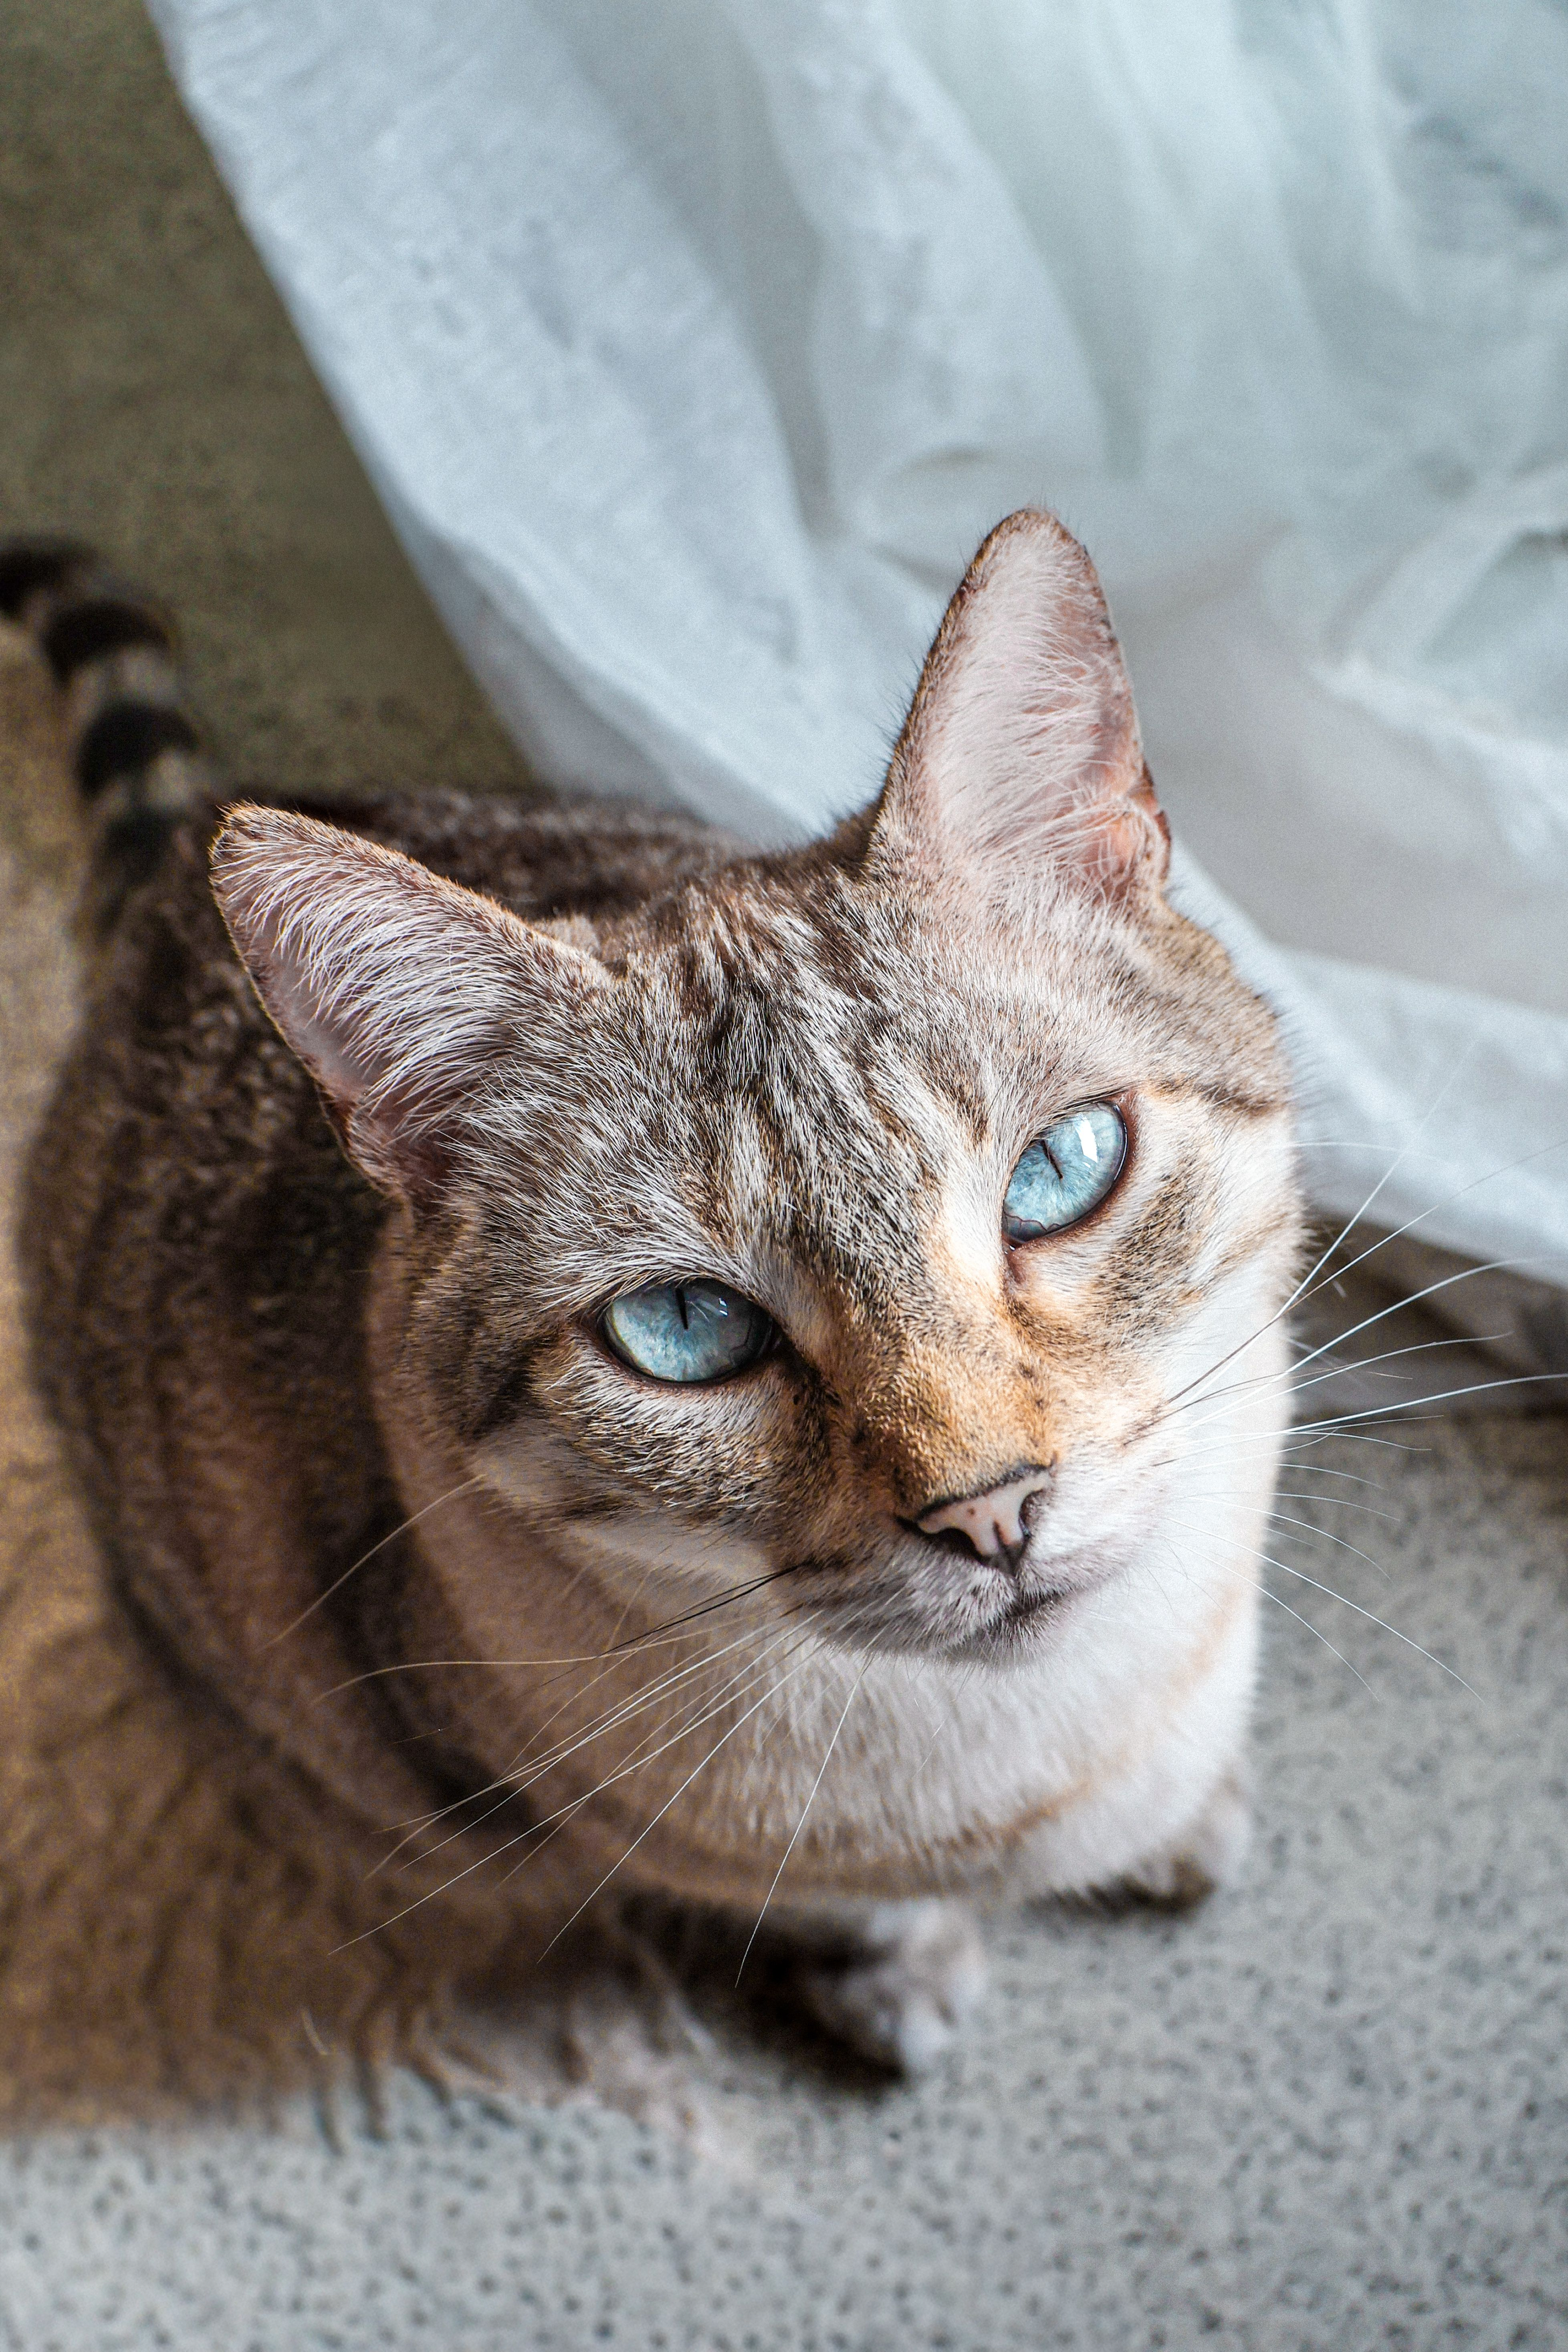

In [75]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

### Answer 

- A text-only **LLM** processes textual input, while a **multimodal model** can process multiple input modalities, such as images plus text.
- The vision model receives visual information from the image in addition to the text prompt. This allows it to identify objects, describe the environment, recognize visible text, and interpret the scene.
- Local vision AI can be used for document analysis, OCR (text extraction from images), industrial quality inspection, education, medical-image preprocessing, and surveillance analysis. Running these models locally can also improve data privacy by keeping sensitive images on the user's device.

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [76]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)

In [77]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "llama3.2:3b"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {
            "model": MODEL,
            "prompt": question,
            "stream": False
        }
        response = requests.post(
            OLLAMA_URL,
            json=data,
            timeout=600
        )
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Writing local-ai-web/app.py


In [78]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [79]:
!pip install -q psutil

In [80]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [82]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = [4, 5]   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3:4b,6.55,3.18,0.0,8.29,220.93,1404,6.70,74.3,4
1,llama3.2:3b,2.02,2.56,0.0,6.76,80.75,759,10.71,89.2,5


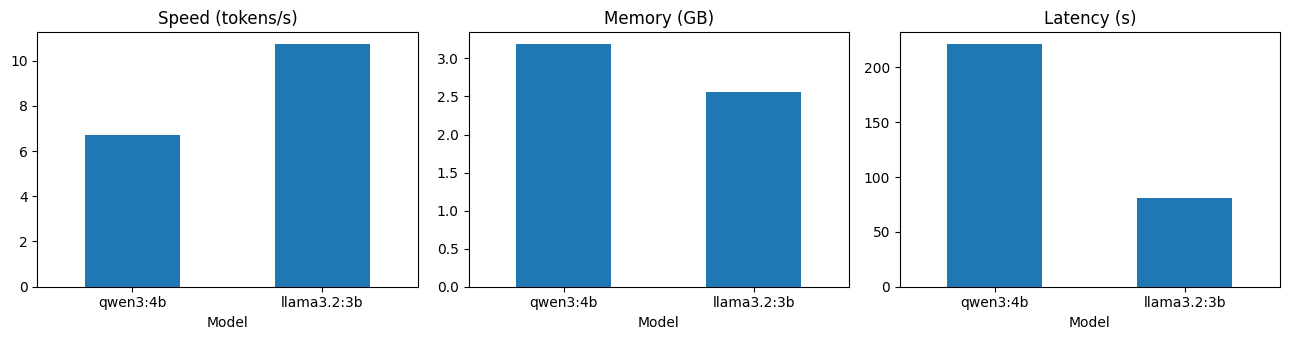

In [83]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

### Discussion 
In my experiment, I compared Qwen3 4B and Llama 3.2 3B.

Qwen is larger (6.55 GB) than Llama (2.02 GB), but Llama was faster, with a response time of 80.75 seconds compared to 220.93 seconds for Qwen.

Llama also used less loaded memory (2.56 GB vs. 3.18 GB) and received a better quality score (5/5 vs. 4/5).

Both models ran locally without recorded GPU memory usage.

Conclusion: Llama 3.2 3B was the better choice for my computer. This shows that a larger model is not always better, and choosing a local model should depend on real performance tests.

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [84]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [85]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [86]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [87]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [88]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [89]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: First, I need to answer the question "What is reinforcement learning?" using only the provided context. The context consists of two files: [course.txt] and [rein. learning.txt].

Let me look at the content:

From [course.txt]:
- Machine learning is a branch of artificial intelligence.
- Supervised learning uses labelled data.
- Unsupervised learning works with unlabelled data.
- Reinforcement learning learns through interaction with an environment using rewards and penalties.

From [reinforcement_learning.txt]:
- Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.

The question is specifically about what reinforcement learning is. I should extract the definition from the context.

In [course.txt], it says: "Reinfo

In [90]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

In [91]:
import requests

response = requests.post(
    "http://localhost:11434/api/generate",
    json={
        "model": "llama3.2:3b",
        "prompt": "What is artificial intelligence? Answer in one sentence.",
        "stream": False
    },
    timeout=600
)

response.raise_for_status()
print(response.json()["response"])

Artificial intelligence (AI) refers to the development of computer systems that can perform tasks that typically require human intelligence, such as learning, problem-solving, and decision-making, using algorithms and data.


## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1.** What is Local AI?

*(answer)*

**Q2.** Difference between a Cloud LLM and a Local LLM?

*(answer)*

**Q3.** What role does Ollama play?

*(answer)*

**Q4.** What is model quantization?

*(answer)*

**Q5.** Why does model size affect memory consumption?

*(answer)*

**Q6.** Why can a smaller model sometimes be preferable?

*(answer)*

**Q7.** Advantages of local inference?

*(answer)*

**Q8.** Disadvantages of local inference?

*(answer)*

**Q9.** Explain the architecture of your Python application.

*(answer)*

**Q10.** Explain the role of the REST API.

*(answer)*

**Q11.** What is RAG?

*(answer)*

**Q12.** Difference between an LLM and a multimodal LLM?

*(answer)*

**Q13.** Compare two local models experimentally.

*(answer + table from Part 16)*

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

*(answer)*

**Q15.** What security risks exist when exposing a local LLM server to a network?

*(Hint: Ollama has no authentication by default; think about `OLLAMA_HOST=0.0.0.0`, unauthorized use of your compute, model/data exposure, prompt injection through documents, and what a reverse proxy with auth/TLS or a firewall would change.)*

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [92]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))

✅ LocalAI_Lab/report.pdf
✅ LocalAI_Lab/README.md
✅ LocalAI_Lab/source/app.py
✅ LocalAI_Lab/source/chatbot.py
✅ LocalAI_Lab/source/rag.py
✅ LocalAI_Lab/source/benchmark.py
✅ LocalAI_Lab/screenshots/01_installation.png
✅ LocalAI_Lab/screenshots/02_model.png
✅ LocalAI_Lab/screenshots/03_chatbot.png
✅ LocalAI_Lab/screenshots/04_python.png
✅ LocalAI_Lab/screenshots/05_rag.png
✅ LocalAI_Lab/screenshots/06_webapp.png

Documents: ['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']
